# c8 · Step 8: Regularisation

Both architecture candidates from c7 (the best **small** and the best **deep** model) are regularised, because
the benefit of regularisation depends on how much a model overfits. Order: augmentation → weight decay →
dropout, each starting from the previous winner.

| # | Technique | Options |
|---|---|---|
| 1 | augmentation (train only, on the GPU) | **none**, geometric, mild (geometric + intensity), strong |
| 2 | weight decay (decoupled, i.e. AdamW for Adam) | **0**, two strengths |
| 3 | dropout before the classifier | **0**, 0.3 |
| 4 | small vs deep | best regularised version of each |

All runs use the protocol from c4 (60-epoch cap, patience 20 on val balanced accuracy), which leaves augmented
runs, which learn more slowly, enough time. Seeds: 3 for the small model; 2 for the
deep model, because it is ~5-10x slower. The `compare` rule accounts for the smaller n with a wider threshold.

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, ".")
from dataclasses import replace
from lib.train import Config, run
from lib.report import run_seeds, compare, pick, log_progress, SEEDS3
from lib.data import ARTIFACTS
from lib.report import protocol; proto = protocol()   # c4 protocol with the raised epoch cap
INPUT = json.loads((ARTIFACTS / "input.json").read_text())
OPTIM = json.loads((ARTIFACTS / "optim.json").read_text())
ARCH = {k: {kk: tuple(vv) if isinstance(vv, list) else vv for kk, vv in v.items()}
        for k, v in json.loads((ARTIFACTS / "arch.json").read_text()).items()}
BASE = replace(Config(exp="c8", name="x", monitor=proto["monitor"], patience=proto["patience"], epochs=proto["epochs"]), **INPUT, **OPTIM)
CAND = {"small": (replace(BASE, **ARCH["small"]), SEEDS3), "deep": (replace(BASE, **ARCH["deep"]), SEEDS3[:2])}
print(OPTIM); print(ARCH)

{'optimizer': 'adam', 'lr': 0.03, 'batch_size': 128, 'schedule': 'none', 'loss': 'focal', 'sampler': 'none'}
{'small': {'widths': (16, 32, 64, 128), 'depths': (1, 1, 1, 1), 'kernel': 5, 'stem_kernel': 5, 'block': 'basic', 'norm': True, 'residual': True, 'downsample': 'avgpool'}, 'deep': {'widths': (16, 32, 64, 128), 'depths': (2, 2, 2, 2), 'kernel': 5, 'stem_kernel': 5, 'block': 'basic', 'norm': True, 'residual': True, 'downsample': 'avgpool'}}


## 1. Augmentation

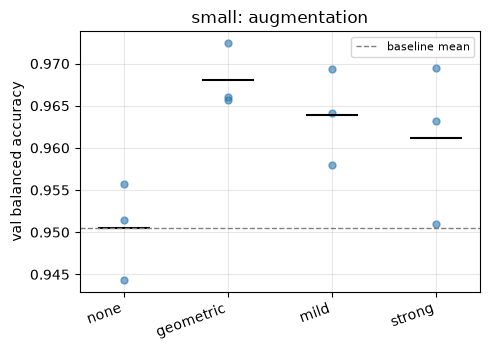

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep,train-val gap
none,0.9505,0.0058,3.0,0.0000,0.0505,0.9463,0.9946,0.9479,57.0000,832308.0,1.0196,0.0450
geometric,0.9680,0.0038,3.0,0.0175,0.0505,0.9641,0.9958,0.9688,76.6667,832308.0,1.0563,0.0221
mild,0.9639,0.0057,3.0,0.0134,0.0505,0.9613,0.9963,0.9583,93.0000,832308.0,1.0661,0.0262
strong,0.9612,0.0094,3.0,0.0107,0.0505,0.9578,0.9962,0.9653,90.0000,832308.0,1.3307,0.0123


small -> chosen augmentation: geometric


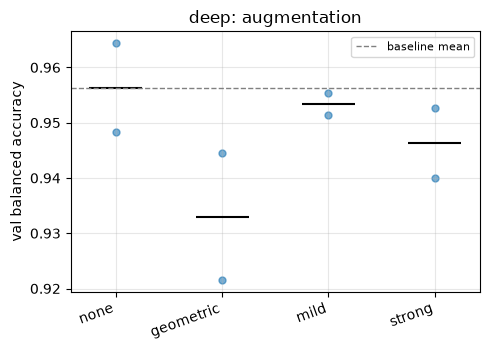

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep,train-val gap
none,0.9564,0.0113,2.0,0.0000,0.0619,0.9556,0.9956,0.9427,86.5,1921268.0,1.7253,0.0428
geometric,0.9330,0.0162,2.0,-0.0233,0.0619,0.9234,0.9950,0.9428,49.0,1921268.0,1.7727,0.0253
mild,0.9534,0.0028,2.0,-0.0030,0.0619,0.9511,0.9947,0.9427,72.5,1921268.0,1.7838,0.0318
strong,0.9463,0.0089,2.0,-0.0101,0.0619,0.9472,0.9973,0.9218,64.5,1921268.0,2.0282,0.0173


deep -> chosen augmentation: none


In [2]:
def gap(rs):  # train minus val balanced accuracy at the selected epoch (overfitting indicator)
    return np.mean([r["history"][r["best_epoch"] - 1]["train_bal_acc"] - r["val"]["bal_acc"] for r in rs])

aug_runs, chosen, tables = {}, {}, {}
for m, (cfg, seeds) in CAND.items():
    aug_runs[m] = {a: run_seeds(replace(cfg, name=f"{m}_aug_{a}", aug=a), seeds) for a in ["none", "geometric", "mild", "strong"]}
    tables[m] = compare(aug_runs[m], "none", f"{m}: augmentation")
    tables[m]["train-val gap"] = [round(gap(rs), 4) for rs in aug_runs[m].values()]
    display(tables[m])
    chosen[m] = pick(tables[m], "none")
    print(m, "-> chosen augmentation:", chosen[m])

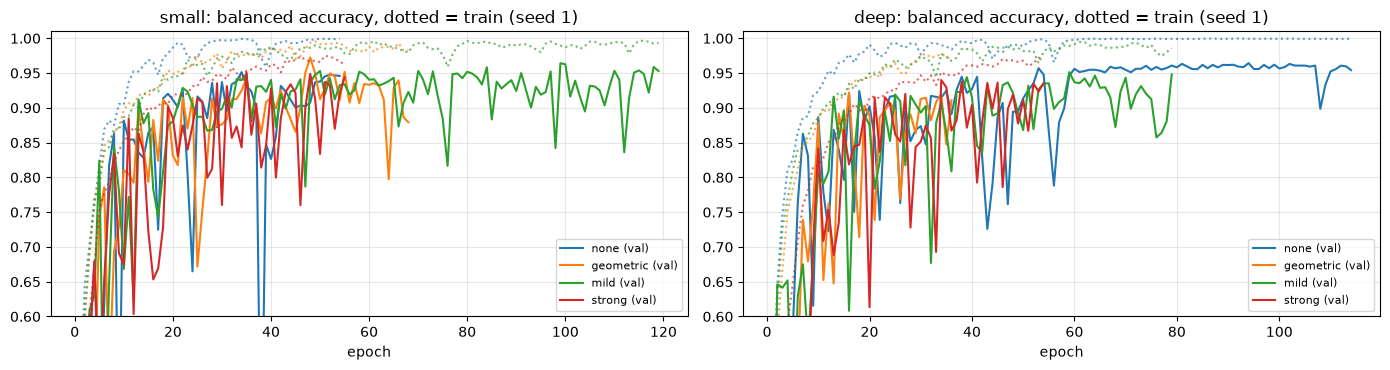

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, m in zip(axes, CAND):
    for a, rs in aug_runs[m].items():
        h = pd.DataFrame(rs[0]["history"])
        l, = ax.plot(h.epoch, h.val_bal_acc, label=f"{a} (val)")
        ax.plot(h.epoch, h.train_bal_acc, ls=":", color=l.get_color(), alpha=0.7)
    ax.set(title=f"{m}: balanced accuracy, dotted = train (seed 1)", xlabel="epoch", ylim=(0.6, 1.01)); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

_TODO aug_

## 2. Weight decay

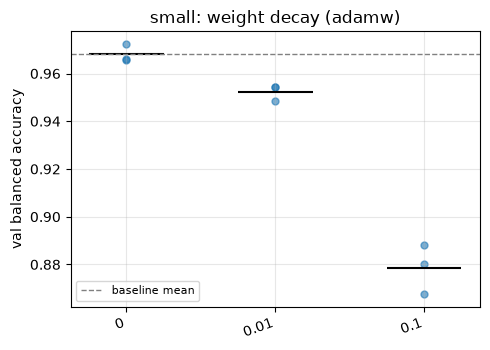

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
0,0.9680,0.0038,3.0,0.0000,0.0505,0.9641,0.9958,0.9688,76.6667,832308.0,1.0563
0.01,0.9524,0.0035,3.0,-0.0157,0.0505,0.9489,0.9951,0.9410,76.3333,832308.0,1.0586
0.1,0.8786,0.0103,3.0,-0.0895,0.0505,0.8661,0.9892,0.9028,50.6667,832308.0,1.0542


small -> chosen weight decay: 0


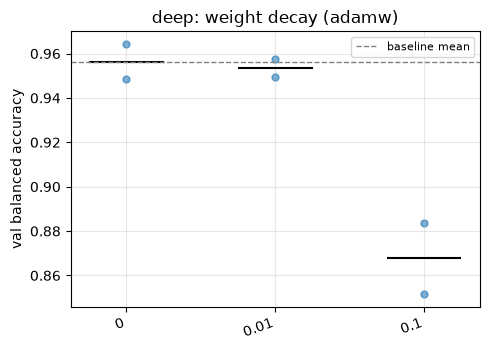

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
0,0.9564,0.0113,2.0,0.0000,0.0619,0.9556,0.9956,0.9427,86.5,1921268.0,1.7253
0.01,0.9535,0.0059,2.0,-0.0029,0.0619,0.9518,0.9960,0.9584,74.5,1921268.0,1.7401
0.1,0.8677,0.0228,2.0,-0.0887,0.0619,0.8638,0.9911,0.8958,54.0,1921268.0,1.7280


deep -> chosen weight decay: 0


In [4]:
WD = [0.01, 0.1] if OPTIM["optimizer"] in ("adam", "adamw") else [5e-4, 5e-3]
wd_runs = {}
for m, (cfg, seeds) in CAND.items():
    cfg = replace(cfg, aug=chosen[m]); CAND[m] = (cfg, seeds)
    opt = "adamw" if OPTIM["optimizer"] in ("adam", "adamw") else OPTIM["optimizer"]
    wd_runs[m] = {"0": aug_runs[m][chosen[m]],
                  **{f"{w:g}": run_seeds(replace(cfg, name=f"{m}_aug_{chosen[m]}_wd{w:g}", optimizer=opt, weight_decay=w), seeds) for w in WD}}
    t = compare(wd_runs[m], "0", f"{m}: weight decay ({opt})"); display(t)
    w = pick(t, "0")
    if w != "0":
        CAND[m] = (replace(cfg, optimizer=opt, weight_decay=float(w)), seeds)
    print(m, "-> chosen weight decay:", w)

_TODO wd_

## 3. Dropout

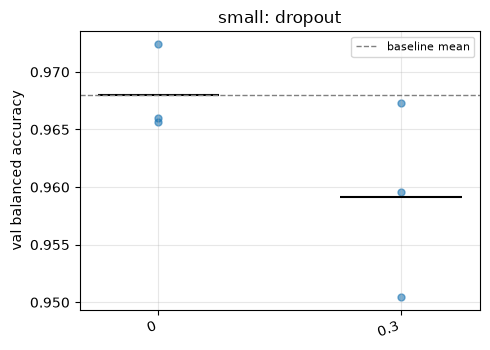

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
0,0.9680,0.0038,3.0,0.0000,0.0505,0.9641,0.9958,0.9688,76.6667,832308.0,1.0563
0.3,0.9591,0.0084,3.0,-0.0089,0.0505,0.9524,0.9964,0.9583,94.3333,832308.0,1.0592


small -> chosen dropout: 0


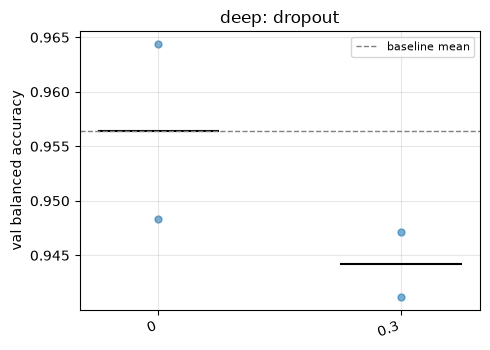

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
0,0.9564,0.0113,2.0,0.0000,0.0619,0.9556,0.9956,0.9427,86.5,1921268.0,1.7253
0.3,0.9442,0.0042,2.0,-0.0122,0.0619,0.9471,0.9963,0.9062,87.5,1921268.0,1.7461


deep -> chosen dropout: 0


In [5]:
do_runs = {}
for m, (cfg, seeds) in CAND.items():
    cur = wd_runs[m]["0" if cfg.weight_decay == 0 else f"{cfg.weight_decay:g}"]
    do_runs[m] = {"0": cur, "0.3": run_seeds(replace(cfg, name=f"{m}_aug_{cfg.aug}_wd{cfg.weight_decay:g}_do0.3", dropout=0.3), seeds)}
    t = compare(do_runs[m], "0", f"{m}: dropout"); display(t)
    d = pick(t, "0")
    if d != "0":
        CAND[m] = (replace(cfg, dropout=0.3), seeds)
    print(m, "-> chosen dropout:", d)

_TODO dropout_

## 4. Small vs deep, both regularised

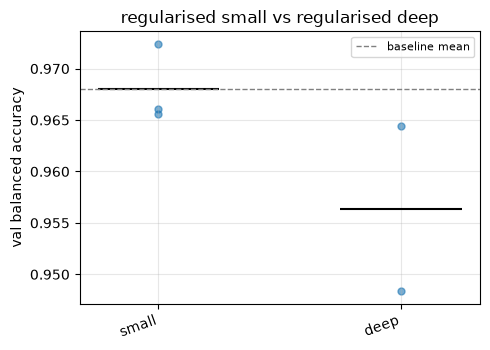

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
small,0.9680,0.0038,3.0,0.0000,0.0505,0.9641,0.9958,0.9688,76.6667,832308.0,1.0563
deep,0.9564,0.0113,2.0,-0.0117,0.0565,0.9556,0.9956,0.9427,86.5000,1921268.0,1.7253


small per-class recall: {'glioma': 0.963, 'meningioma': 0.957, 'no_tumor': 0.969, 'pituitary': 0.984}
deep per-class recall: {'glioma': 0.955, 'meningioma': 0.944, 'no_tumor': 0.943, 'pituitary': 0.983}


In [6]:
final = {m: do_runs[m]["0.3" if cfg.dropout else "0"] for m, (cfg, _) in CAND.items()}
t = compare(final, "small", "regularised small vs regularised deep"); display(t)
for m, rs in final.items():
    print(m, "per-class recall:", pd.DataFrame([r["val"]["recall"] for r in rs]).mean().round(3).to_dict())

_TODO final_

## Decisions

_TODO summary_

In [7]:
WINNER = pick(t, "small")   # highest mean val balanced accuracy wins, whatever its size
cfg = CAND[WINNER][0]
REG = dict(aug=cfg.aug, optimizer=cfg.optimizer, weight_decay=cfg.weight_decay, dropout=cfg.dropout)
_ = (ARTIFACTS / "reg.json").write_text(json.dumps({"winner": WINNER, "arch": ARCH[WINNER], **REG}, default=list))
for m in CAND: _ = log_progress(f"c8 regularised {m}", final[m])
WINNER, REG

('small',
 {'aug': 'geometric',
  'optimizer': 'adam',
  'weight_decay': 0.0,
  'dropout': 0.0})